# 🧠 Lab 0 — ML Pipeline Review: Scikit-learn & PyTorch



---
This lab walks through the **complete ML workflow** using two complementary frameworks:

| Part | Framework | Task |
|------|-----------|------|
| **Part 1** | Pandas + Scikit-learn | Titanic survival prediction (binary classification) |
| **Part 2** | PyTorch | Digits recognition (multi-class classification) |

**Estimated time:** 1.5 hours  
**Goal:** By the end you will be able to preprocess tabular data, train classical ML models, and build + train a neural network from scratch in PyTorch.

**Recommendations**:
* Disable AI code completion support.
* Challenge yourself to carry out the programming alone and take the opportunity to refresh your Python programming skills.
* Answer all questions

---

## 📦 Part 1 — ML Pipeline with Pandas & Scikit-learn

A typical ML pipeline involves these steps:
1. **Load & explore** the data
2. **Split** into train/test (with stratification)
3. **Clean**: handle missing values, remove duplicates
4. **Select**: handle missing values, remove duplicates
5. **Encode** categorical features
6. **Scale** numerical features
7. **Train & evaluate** one or more classifiers

> ⚠️ Always fit transformers **only on the training set**, then apply them to both sets to avoid data leakage.

### 1.1 — Imports and Load


In [ ]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("✅ Libraries loaded")

✅ Libraries loaded




The [Titanic dataset](https://www.kaggle.com/c/titanic) contains passenger information and whether they survived.  
We want to predict the column **`survived`** (0 = no, 1 = yes).

In [ ]:
# Load dataset from OpenML
df, y = fetch_openml('titanic', version=1, as_frame=True, parser='auto', return_X_y=True)

# The "survived" column contains the target variable
df["survived"] = y

# Print the number of samples in the dataset
print(f"Number of samples in the dataset: {len(df)}")

Number of samples in the dataset: 1309




Pandas [DataFrames](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html) have useful methods and attributes  to manipulate and analyze data efficiently.

Some methods and attributes are useful for getting a quick overview of your data. Some examples include:
- `df.head()`: This method returns the first *n* rows of the DataFrame, where *n* is a parameter that you can specify. If you do not specify n, it defaults to 5. This is particularly useful for quickly inspecting the beginning of your dataset to understand its structure and the type of data it contains.
- `df.info()`: This method provides a concise summary of the DataFrame, including the number of non-null entries in each column, the data type of each column, the memory usage, the number of columns, and the range index. It can be useful for getting a quick overview of the DataFrame's structure and to identify columns with missing values.
- `df.columns()`: This attribute can be used to view or modify the column names. For example, you can use df.columns.tolist() to get a list of all column names.
- `df.describe()`: This method generates descriptive statistics that summarize the central tendency, dispersion, and shape of the dataset’s distribution, excluding *NaN* values. It works on numeric and object data types, providing information such as mean, standard deviation, minimum, maximum, and quartile values for numeric data, and count, unique, top, and frequency for object data (e.g., strings or timestamps).


In [ ]:
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (1309, 14)


,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest,survived
0,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO",1
1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON",1
2,1,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0
3,1,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON",0
4,1,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0


In [ ]:
# Quick overview
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   pclass     1309 non-null   int64   
 1   name       1309 non-null   object  
 2   sex        1309 non-null   category
 3   age        1046 non-null   float64 
 4   sibsp      1309 non-null   int64   
 5   parch      1309 non-null   int64   
 6   ticket     1309 non-null   object  
 7   fare       1308 non-null   float64 
 8   cabin      295 non-null    object  
 9   embarked   1307 non-null   category
 10  boat       486 non-null    object  
 11  body       121 non-null    float64 
 12  home.dest  745 non-null    object  
 13  survived   1309 non-null   category
dtypes: category(3), float64(3), int64(3), object(5)
memory usage: 116.8+ KB


The `"survived"` column contains the target variable (i.e., the variable that you want to predict).

Some datasets contain a **balanced** number of samples for each label. Thus, each category of data is equally represented. However, many real-world datasets are **imbalanced**, meaning they have a disproportionate number of samples in one or more classes than others.

Highly **imbalanced** datasets can cause the model to become biased towards the more frequently represented class(es), thereby reducing the model's ability to generalize well across all categories. In such cases, the model trained may perform well on the majority class(es) but poorly on the minority class(es), because it has not had enough data to learn from for the underrepresented categories. Imbalance can significantly affect the performance and fairness of predictive models, leading to misleadingly high accuracy scores that do not accurately reflect the model's ability to predict less frequent classes.

Run the next cell to count the number of samples for each class label. This is useful to verify if the dataset is **balanced** or **imbalanced**.

In [ ]:
# Class balance — important for choosing metrics!
print("Class distribution:")
print(df["survived"].value_counts())
# print(f"\nImbalance ratio: {df['survived'].value_counts()[0]/df['survived'].value_counts()[1]:.2f}:1")
print(f"\nImbalance ratio: {df['survived'].value_counts().iloc[0]/df['survived'].value_counts().iloc[1]:.2f}:1")

Class distribution:
survived
0    809
1    500
Name: count, dtype: int64

Imbalance ratio: 1.62:1


### 1.2 — Train / Test Split with Stratification

The first step involves splitting your dataset into distinct subsets to ensure that your model can generalize well to unseen data. This step is crucial for evaluating the performance of your model in an unbiased manner.

Datasets are usually split into the following subset:
- **Training Set**: Subset of your data used to train your model. It is the largest portion from which your model learns the underlying patterns to perform accurate predictions.

- **Validation Set**: (Optional but highly recommended) Subset used to fine-tune the model's hyperparameters and evaluate which models, configurations, or hyperparameters is the best performance. It acts as a proxy for the test set during the development phase.

- **Test Set**: Subset used to evaluate the final model's performance after it has been trained and validated. It provides an assessment of how well your model has learned to generalize from the training data to new, unseen data.

In this lab, we will only use training and test set for semplicity, and due to the low number of samples in the dataset.



#### Exercise 1.2

Split the dataset into **train** and **test** datasets.

In this case, the dataset is **imbalanced**. Therefore, it is recommended to split using stratification (i.e., the class label distribution will be preserved during the splitting).

Because the dataset is **imbalanced**, we use `stratify=` to preserve the class ratio in both splits.

**Split** with 80% of samples for training and 20% of samples for validation. **Shuffle** the dataset before splitting, and perform the **stratification** by label. Replace `None` with your code.


<details>    
<summary>
    <font size="3" color="darkgreen"><b>Hints</b></font>
</summary>
<p>
<ul>
    <li> To split a dataset you can use the `train_test_split` function of Scikit-learn (<a href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html" >link</a>).
</ul>
</p>

In [ ]:
#@title Exercise 1.2 Solution

#### START CODE HERE ####
# Split 80% train / 20% test, shuffle=True, random_state=42, stratify by 'survived'
df_train, df_test = train_test_split(df, test_size=0.2, shuffle=True, random_state=42, stratify=df['survived'])
#### END CODE HERE ####

print(f"Train: {len(df_train)} samples | Test: {len(df_test)} samples")
print("\nTrain class distribution:")
print(df_train["survived"].value_counts())

Train: 1047 samples | Test: 262 samples

Train class distribution:
survived
0    647
1    400
Name: count, dtype: int64


### 1.3 — Handle Missing Values

Machine learning algorithms require that all the input values are in a **numerical** formal. However, real-world datasets are often "dirty". For instance, they can contain missing values for some columns and records. Before training your ML models, you should handle missing values.

You should first check if **null** values are present in your dataset. Pandas Dataframes have many useful methods to check for null values in your dataset.
- `df.isnull()` or `df.isna()`: They return a DataFrame with the same shape as the input DataFrame, but containing boolean values (True or False) indicating the presence of null values.
- `df.notnull()` or `df.notna()`: The opposite of isnull() and isna().


**Rule:** compute statistics (mean, median…) on the **training set only**, then apply to both sets.

In [ ]:
# Count NaN per column
nan_train = df_train.isna().sum()
nan_test  = df_test.isna().sum()

print("Missing values — Train:")
print(nan_train[nan_train > 0])
print("\nMissing values — Test:")
print(nan_test[nan_test > 0])

Missing values — Train:
age          209
fare           1
cabin        822
boat         658
body         955
home.dest    450
dtype: int64

Missing values — Test:
age           54
cabin        192
embarked       2
boat         165
body         233
home.dest    114
dtype: int64


In several columns of the dataset, missing values are present, specified with `NaN` (i.e., not a number).

There are several strategies for handling missing data, some examples include:
1. **Deletion**: Discard entire rows/columns containing missing
values.
2.  **Imputation**: Replace missing values with some imputed values (e.g., mean, median, constant, etc.).

3.  **Inference**: Use other data points to train a model that can predict the missing values.

> #### 1. Discarding missing values
  * You can **remove** rows or columns containing missing values using the `df.drop(...)` method of Pandas DataFrames.
  * You can also remove rows containing missing values in a specific column specifying the `columns` parameter (e.g., `df.drop(columns = ["column_name"])`). In this case,  all rows containing a missing value in the `column_name` column are removed.
  * Note that, `df.drop()` returns a new DataFrame. Therefore, you should re-assign to `df` the new DataFrame (e.g., `df = df.drop()`) or set the `inplace` parameter to `True` (e.g., `df.drop(inplace=True)`).

> #### 2. Imputing missing values
  * You can impute values on missing data with Pandas with the `df.fillna()` method and specify the new value that will replace the `NaN` values. For instance, you can replace `NaN` values with the column mean with `df.fillna({'column_name': df['column_name'].mean()})`.
  *  The `df.fillna()` method returns a new DataFrame by replacing the null values with the specified value unless you specify the `inplace` parameter to `True`.
  * You can replace missing values using a descriptive statistic (e.g., mean, median, or most frequent) along each column, or using a constant value.
    - `"mean"`: replace missing values using the *mean* along each column (only for numeric data).
    - `"median"`: replace missing values using the *median* along each column (only for numeric data).
    - `"most_frequent"`: replace missing using the *most frequent value* along each column (for both strings and numeric data).


> #### 3. Predicting missing values
Using models to predict the missing values is uncovered in this lab. However, the idea is to simply train a machine learning model (e.g., linear regression) to predict missing values. If you are interested, you can read more about it [here](https://medium.com/machine-learning-mastery/5-ways-to-handle-missing-values-in-python-4fe6a625e251).

#### Exercise 1.3.1

Fill **null values** in the column `age` with the **mean** of the column `age` in the training and test set.

<details>    
<summary>
    <font size="3" color="darkgreen"><b>Hints</b></font>
</summary>
<p>

<ul>
    <li> Remember that all the statistics must be computed on the training set only. Therefore, the null values in the test set must be replaced by the mean of the training.
</ul>
</p>

In [ ]:
#@title Exercise 1.3.1 Solution

print(f'Number of null values in Train before pre-processing: {df_train.age.isnull().sum()}/{len(df_train)}')
print(f'Number of null values in Test before pre-processing: {df_test.age.isnull().sum()}/{len(df_test)}')

#### START CODE HERE (~2 lines) ####
# Fill 'age' NaN with the TRAINING mean
df_train.fillna({'age': df_train['age'].mean()}, inplace=True)
df_test.fillna({'age': df_train['age'].mean()}, inplace=True)
#### END CODE HERE ####

print(f'Number of null values in Train before pre-processing: {df_train.age.isnull().sum()}/{len(df_train)}')
print(f'Number of null values in Test before pre-processing: {df_test.age.isnull().sum()}/{len(df_test)}')

Number of null values in Train before pre-processing: 209/1047
Number of null values in Test before pre-processing: 54/262
Number of null values in Train before pre-processing: 0/1047
Number of null values in Test before pre-processing: 0/262


#### Exercise 1.3.2

Fill **null values** in the column `fare` with the **median** of the column `fare` in the training and test set. Why median? Because fare is typically a more skewed feature



<details>    
<summary>
    <font size="3" color="darkgreen"><b>Hints</b></font>
</summary>
<p>

<ul>
    <li> Remember that all the statistics must be computed on the training set only. Therefore, the null values in the test set must be replaced by the median of the training.
</ul>
</p>

In [ ]:
#@title Exercise 1.3.2 Solution

#### START CODE HERE (~2 lines) ####
# Fill 'fare' NaN with the TRAINING median
# Why median? Because fare is typically a more skewed feature
df_train.fillna({'fare' : df_train['fare'].median()}, inplace=True)
df_test.fillna({'fare' : df_train['fare'].median()}, inplace=True)
#### END CODE HERE ####

#### Exercise 1.3.3

Fill **null values** in the column `embarked` with the **most frequent value** of the column `embarked` in the training and test set. Hint: `df['embarked'].mode()` return a list of the most frequent values.

<details>    
<summary>
    <font size="3" color="darkgreen"><b>Hints</b></font>
</summary>
<p>

<ul>
    <li> Remember that all the statistics must be computed on the training set only. Therefore, the null values in the test set must be replaced by the most frequent value of the training.
</ul>
</p>

In [ ]:
#@title Exercise 1.3.3 Solution

#### START CODE HERE (~ 3 line) ####
most_freq = df_train['embarked'].mode()[0]
df_train.fillna({'embarked': most_freq}, inplace=True)
df_test.fillna({'embarked': most_freq}, inplace=True)
#### END CODE HERE ####
print(f"Remaining NaN — Train: {df_train.isna().sum().sum()} | Test: {df_test.isna().sum().sum()}")

Remaining NaN — Train: 2885 | Test: 704


In [ ]:
#@title Exercise 1.3.3 Solution Alternative


#alternative sol
#### START CODE HERE (~ 3 line) ####
imp = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
df_train['embarked'] = imp.fit_transform(df_train[['embarked']]).ravel()
df_test['embarked'] = imp.transform(df_test[['embarked']]).ravel()
#### END CODE HERE ####


#### Exercise 1.3.4

Drop columns with **too many missing values**  (i.e., 'boat', 'body', 'home.dest', 'cabin')

In [ ]:
#@title Exercise 1.3.4 Solution

#### START CODE HERE (~3 lines) ####
cols_to_drop = ['boat', 'body', 'home.dest', 'cabin']
df_train.drop(columns=cols_to_drop, inplace=True, errors='ignore')
df_test.drop(columns=cols_to_drop, inplace=True, errors='ignore')
#### END CODE HERE ####
print(f"Remaining NaN — Train: {df_train.isna().sum().sum()} | Test: {df_test.isna().sum().sum()}")



Remaining NaN — Train: 0 | Test: 0


### 1.4 — Feature Selection and Engineering

**Feature selection** is a critical step in the machine learning pipeline, as it involves choosing the most relevant features (or variables) that contribute to the predictive power of a model. The goal of feature selection is not only to improve the model's performance but also to reduce the computational complexity and enhance the interpretability of the model.

Identifiers, unique codes, etc., are usually useless features that must be removed.

You can learn more about advanced feature selection techniques [here](https://nathanrosidi.medium.com/feature-selection-techniques-in-machine-learning-82c2123bd548).

#### Exercise 1.4

Drop columns that are not useful (i.e., 'ticket', 'name')

In [ ]:
#@title Exercise 1.4 Solution

#### START CODE HERE (~3 lines) ####
cols_to_drop = ['ticket', 'name']
df_train.drop(columns=cols_to_drop, inplace=True, errors='ignore')
df_test.drop(columns=cols_to_drop, inplace=True, errors='ignore')
#### END CODE HERE ####

Another crucial pre-processing step in the machine learning pipeline is **feature engineering**, which involves creating new features or modifying existing ones to improve the performance of a machine learning model. Spefically, it can be useful to:
- **Improve model accuracy**: Effective modified features can capture essential information, making it easier for models to learn.
- **Improve model's generalizability**: By capturing the underlying patterns in the data more effectively, feature engineering can help models perform better on unseen data.
- **Reduce the need for complex models**: Simpler models with the right features can outperform complex models with a raw set of features.

In [ ]:
df_train.head()

,pclass,sex,age,sibsp,parch,fare,embarked,survived
999,3,female,29.604316,0,0,7.7500,Q,1
392,2,female,24.000000,1,0,27.7208,C,1
628,3,female,11.000000,4,2,31.2750,S,0
1165,3,male,25.000000,0,0,7.2250,C,0
604,3,female,16.000000,0,0,7.6500,S,1


The next cell plots a **correlation** matrix of the input features with respect to the target variable. The **correlation matrix** is a powerful tool in the data pre-processing phase, especially when you're trying to understand the relationships between your input features and the target variable. Specifically, the **correlation matrix** can be used to:
- **Identify Relationships**: It helps in identifying the linear relationship between the input features and the target variable. A high positive or negative correlation indicates a strong relationship, whereas a correlation close to zero suggests no linear relationship.
- **Feature Selection**: By analyzing the correlation matrix, you can identify and eliminate features that are highly correlated with each other but not with the target variable. This is because highly correlated features contribute redundant information, which can lead to overfitting.
- **Insights for Feature Engineering**: Understanding the relationships between features can also provide insights for feature engineering, such as creating new features that are combinations of existing ones.

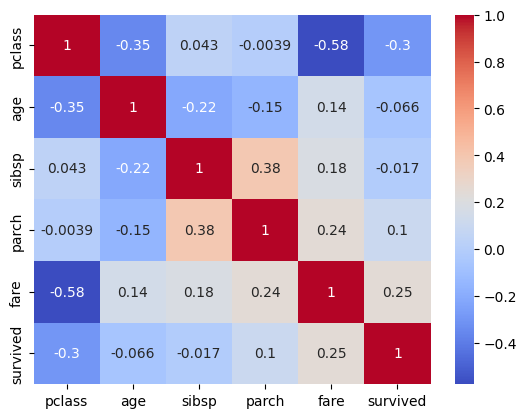

In [ ]:
df_corr= pd.concat([df_train[['pclass',  'age', 'sibsp', 'parch', 'fare']], df_train['survived']], axis = 1)

g = sns.heatmap(df_corr.corr(),
                annot=True,
                cmap = "coolwarm")

The correlation matrix can suggest thst `parch` and `sibsp` seem to be  correlated. A new feature could be added to the model (see later).



### 1.5 — Encode Categorical Features

ML models require **numerical** inputs.  

Machine learning algorithms operate on numerical data, making it essential to convert any categorical input features into a numerical format before training your model. This process, known as **feature encoding**. Proper encoding of input features ensures that the algorithm can interpret the data correctly, leading to more accurate models. Note that this step depends on your algorithm. For instance, Decision trees and their ensembles (e.g., Random Forests) can handle categorical data naturally (depending on the implementation), but many models (such as linear regression, logistic regression, and neural networks) require numerical input.

Common encoding techniques include:
- **One-Hot Encoding**: For each unique category value, a new binary column is created. A category value is represented by a 1 in its corresponding column and 0s in all others. This method avoids implying an ordinal relationship but increases the feature space. For instance, a variable color containing three possible values, e.g., `red`, `green`, and `blue`, will create three additional columns: `color_red`, `color_green`, and `color_blue`. To represent the color green, you will represent the input with the following vector `[0, 1, 0]`. The main drawback of one-hot encoding is that it can significantly increase the dataset's sparsity (i.e., the number of zeros). Another possible drawback is that, if data has a natural order to the categories (e.g., low, medium, high) one-hot encoding can lose this information (use ordinal encoding in this case).
- **Label Encoding**: Each unique category value is assigned an integer value. This method is straightforward but implies an ordinal relationship between categories, which may not always be appropriate.
- **Ordinal Encoding**: Similar to label encoding, but the integer assignments are made based on the order specified by the user, making it suitable for ordinal data.


We use **Label Encoding** (binary categories) and **One-Hot Encoding** (multi-value categories).

In [ ]:
# Label-encode binary categorical column 'sex'
le = LabelEncoder()
le.fit(df_train['sex'])
df_train['sex'] = le.transform(df_train['sex'])
df_test['sex']  = le.transform(df_test['sex'])

# One-hot encode 'embarked' (S, C, Q)
df_train = pd.get_dummies(df_train, columns=['embarked'], drop_first=True)
df_test  = pd.get_dummies(df_test,  columns=['embarked'], drop_first=True)

# Align columns (test may be missing a column if a category is absent)
df_train, df_test = df_train.align(df_test, join='left', axis=1, fill_value=0)

print("Columns after encoding:", df_train.columns.tolist())

Columns after encoding: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'survived', 'embarked_Q', 'embarked_S']


### 1.6 — Normalization and Standardization

Some machine learning algorithms require input features to be **normalized** or **standardized** to work correctly, as this can significantly impact the performance of the model, especially in algorithms that rely on distance computation or gradient descent optimization.

**Normalization** and **standardization** are two fundamental pre-processing steps that help to bring the data onto a common scale, making it easier to process by an algorithm. While both methods scale the data, their methods and purposes differ. The choice between normalization and standardization depends on the specific requirements of the algorithm and the nature of the data.





A **normalization** technique is **Min-Max** normalization. It is a simple tehcnique that rescales the range of features into `[0, 1]`. This is particularly useful when the parameters have to be bounded within a fixed range. It's also useful in algorithms that compute distances between data points and need normalization to ensure that each feature contributes equally to the result.

The formula for **Min-Max normalization** is:

$$ x\_norm = \frac{(x - x_{min})}{(x_{max} - x_{min})} $$

Where:
- $x$ is the original value.
- $x_{min}$ and $x_max$ are the minimum and the maximum of the feature.
- $x_{norm}$ is the normilized value.

Scikit-Learn provides you an useful class to perform the **Min-Max** normalization, namely [MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html).

<br><br>

A widely used **standardization** technique is the **Z-score** normalization. This method involves rescaling the features so they have the properties of a standard normal distribution with zero mean $\mu=0$ and standard deviation one $\sigma = 1$. Standardization is crucial in cases where the data follows a Gaussian distribution and when the algorithm assumes data to be centered around zero.

The formula for **Z-score normalization** is:
$$ x_{standardized} = \frac{(x - \mu)}{\sigma}$$

Where:
- $x$ is the original value.
- $\mu$ is the mean of the feature values.
- $\sigma$ is the standard deviation of the feature values.
- $ x_{standardized}$ is the standardized value.

Unlike Min-Max normalization, standardization does not bind values to a specific range, which makes it useful for features with outliers or many variances. Algorithms like Support Vector Machines, Linear Regression, and Logistic Regression benefit significantly from standardization because it enhances their convergence in optimization algorithms.

Scikit-Learn provides you an useful class to perform the **Z-score** normalization, namely [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).

We keep a subset of informative features and apply `StandardScaler` (zero mean, unit variance).

In [ ]:
feature_cols = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
                'embarked_Q', 'embarked_S']

X_train = df_train[feature_cols].astype(float)
X_test  = df_test[feature_cols].astype(float)

y_train = df_train['survived'].astype(int)
y_test  = df_test['survived'].astype(int)

# Standardize
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # fit + transform on train
X_test  = scaler.transform(X_test)        # only transform on test

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")

X_train shape: (1047, 8) | X_test shape: (262, 8)


### 1.7 — Train & Evaluate Classifiers

Scikit-Learn offers a wide range of pre-implemented classification algorithms. You can explore the available Scikit-Learn classification algorithms [here](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning).

Training a Scikit-Learn model typically involves the following steps:

- **Instantiate the model**: Select the model and create the model object by settings its parameters.
- **Training the Model**: Fit your model to the training data using the `.fit()` method.
- **Evaluating the Model**: Assess the model's performance on the testing set using metrics such as accuracy, precision, recall, and the confusion matrix. Once the model is trained, you can use the `.predict()` method.
- **Parameter Tuning**: Optionally, use cross-validation and grid search to find the best model parameters.

You can learn more about Scikit-Learn evaluation metrics [here](https://scikit-learn.org/stable/modules/model_evaluation.html).

Scikit-Learn also provides useful functions for [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html).

We train three models and compare them using **precision, recall, F1-score** and the **confusion matrix**.

> 💡 Because the dataset is imbalanced, **accuracy alone is misleading** — prefer F1 score.

The next cells train and evaluate a **LogisticRegression** model.

#### Exercise 1.7.1

Train a [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) and evaluate its performance. Store the model prediction in `y_pred_lr`

In [ ]:
#@title Exercise 1.7.1 Solution
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score


#### START CODE HERE ####

# Initialize the model
lr_model = LogisticRegression(max_iter=500, random_state=42)  # Increasing max_iter if convergence warning occurs

# Train the model
lr_model.fit(X_train, y_train)

# Predict
y_pred_lr = lr_model.predict(X_test)

#Evaluate the model
lr_acc = accuracy_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr, average='macro')

# Print accuracy and F1 Score
print(f"Accuracy: {lr_acc:.2f}")
print(f"F1: {lr_f1:.2f}")

#### END CODE HERE ####

Accuracy: 0.81
F1: 0.79


Remember that, when the dataset is **imbalanced**, `F1 score` and `recall` are more useful metrics than `accuracy`.

Scikit-Learn provides you a useful function to compute several evaluation metrics, namely [classification_report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html).

In [ ]:

labels = ["Not-Survived", "Survived"]

print("=" * 45)
print("Logistic Regression")
print("=" * 45)
classification_report_lr = classification_report(y_test, y_pred_lr, target_names=labels)
print(classification_report_lr)

Logistic Regression
              precision    recall  f1-score   support

Not-Survived       0.83      0.86      0.85       162
    Survived       0.76      0.71      0.74       100

    accuracy                           0.81       262
   macro avg       0.80      0.79      0.79       262
weighted avg       0.80      0.81      0.80       262



The next cell plots the confusion matrix. The confusion matrix is a useful tool for evaluating the performance of classification models.
It provides a visual summary of how well the model predicts across different classes, allowing you to see not just the overall accuracy but also more specific details about where the model is making errors.

However, in this case the classification task is binary, so the confusion matrix is not very indicative. However, code is given to show how it can be fastly implemented using Scikit-Learn.

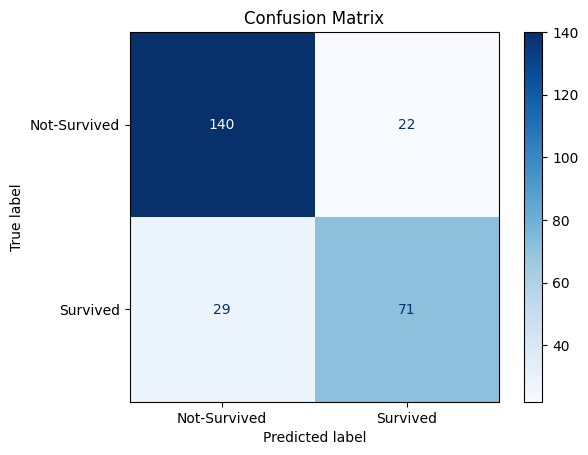

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

cmd = ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_lr, cmap=plt.cm.Blues)
ax = cmd.ax_
ax.set_title('Confusion Matrix')
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
plt.show()

#### Exercise 1.7.2

Train a [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) and evaluate its performance. Store the model prediction in `y_pred_dt`

In [ ]:
#@title Exercise 1.7.2 Solution


labels = ["Not-Survived", "Survived"]

# ── Decision Tree ────────────────────────────────────────────
#### START CODE HERE ####
# Train a DecisionTreeClassifier (max_depth=5), 3 lines of code:
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
#### END CODE HERE ####

print("=" * 45)
print("Decision Tree")
print("=" * 45)
print(classification_report(y_test, y_pred_dt, target_names=labels))

Decision Tree
              precision    recall  f1-score   support

Not-Survived       0.82      0.93      0.87       162
    Survived       0.86      0.66      0.75       100

    accuracy                           0.83       262
   macro avg       0.84      0.80      0.81       262
weighted avg       0.83      0.83      0.82       262



#### Exercise 1.7.3

Train a [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) and evaluate its performance.  Store the model prediction in `y_pred_rf`

In [ ]:
#@title Exercise 1.7.3 Solution


# ── Random Forest ────────────────────────────────────────────
#### START CODE HERE ####
# Train a RandomForestClassifier (max_depth=5), 3 lines of code:
rf_model = RandomForestClassifier(max_depth=5, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
#### END CODE HERE ####

print("=" * 45)
print("Random Forest")
print("=" * 45)
print(classification_report(y_test, y_pred_rf, target_names=labels))

Random Forest
              precision    recall  f1-score   support

Not-Survived       0.85      0.91      0.88       162
    Survived       0.84      0.74      0.79       100

    accuracy                           0.85       262
   macro avg       0.85      0.83      0.83       262
weighted avg       0.85      0.85      0.85       262



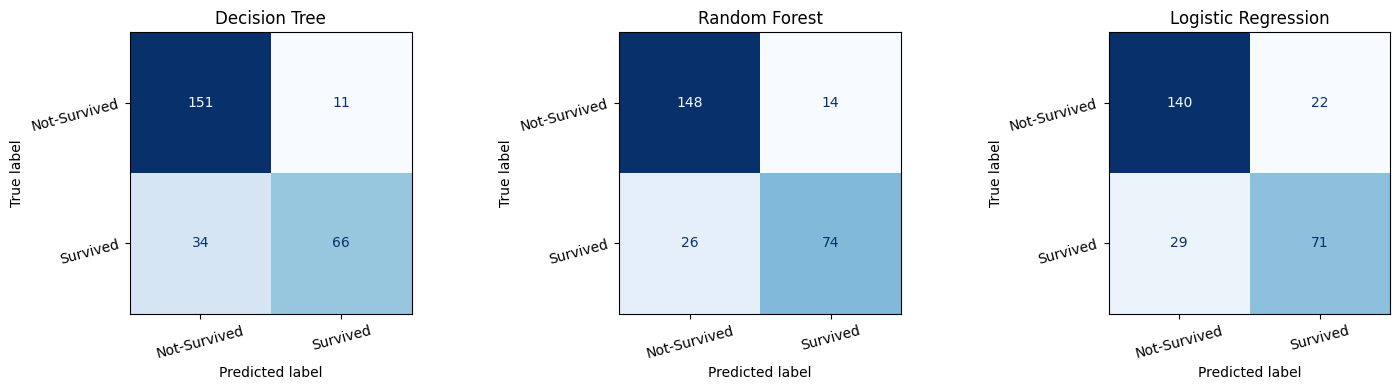

In [ ]:
# ── Confusion matrix for the best model ──────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (model_name, y_pred) in zip(axes, [
        ("Decision Tree", y_pred_dt),
        ("Random Forest", y_pred_rf),
        ("Logistic Regression", y_pred_lr)]):
    cmd = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues",
                                                   colorbar=False)
    ax.set_title(model_name)
    ax.set_xticklabels(labels, rotation=15)
    ax.set_yticklabels(labels, rotation=15)
plt.tight_layout()
plt.show()

### 🔍 Part 1 — Reflection Questions

1. Which model achieves the best F1-score for the *Survived* class? Why might this differ from accuracy?
2. What would happen if we fitted the `StandardScaler` on the **entire** dataset before splitting?
3. Can you think of a feature that could improve the model (e.g., combining `sibsp` + `parch`)? Add it to the dataset and re-train the models.

---

### 1.8 — Feature Engineering: Adding `family_size`





#### Exercise 1.8 (Optional)

Let's create a new feature `family_size` by combining `sibsp` and `parch` and adding 1 for the passenger themselves. Then, we will re-train the models with this new feature.

In [ ]:
#@title Exercise 1.8 Solution


# Create family_size feature
#### START CODE HERE ####
df_train['family_size'] = df_train['sibsp'] + df_train['parch'] + 1
df_test['family_size'] = df_test['sibsp'] + df_test['parch'] + 1

# Update feature columns to include 'family_size'
feature_cols_new = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'family_size',
                    'embarked_Q', 'embarked_S']

X_train_new = df_train[feature_cols_new].astype(float)
X_test_new  = df_test[feature_cols_new].astype(float)

y_train_new = df_train['survived'].astype(int)
y_test_new  = df_test['survived'].astype(int)
#### END CODE HERE ####

# Re-standardize with the new feature
scaler_new = StandardScaler()
X_train_new = scaler_new.fit_transform(X_train_new)
X_test_new  = scaler_new.transform(X_test_new)


print(f"X_train_new shape: {X_train_new.shape} | X_test_new shape: {X_test_new.shape}")

X_train_new shape: (1047, 9) | X_test_new shape: (262, 9)


### 1.9 — Re-Train & Evaluate Classifiers with new feature

#### Exercise 1.9 (Optional)

In [ ]:
#@title Exercise 1.9 Solution


labels = ["Not-Survived", "Survived"]

# ── Decision Tree ────────────────────────────────────────────
#### START CODE HERE ####
dt_model_new = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model_new.fit(X_train_new, y_train_new)
y_pred_dt_new = dt_model_new.predict(X_test_new)
#### END CODE HERE ####

print("=" * 45)
print("Decision Tree (with family_size)")
print("=" * 45)
print(classification_report(y_test_new, y_pred_dt_new, target_names=labels))

# ── Random Forest ────────────────────────────────────────────
#### START CODE HERE ####
rf_model_new = RandomForestClassifier(max_depth=5, random_state=42)
rf_model_new.fit(X_train_new, y_train_new)
y_pred_rf_new = rf_model_new.predict(X_test_new)
#### END CODE HERE ####

print("=" * 45)
print("Random Forest (with family_size)")
print("=" * 45)
print(classification_report(y_test_new, y_pred_rf_new, target_names=labels))

# ── Logistic Regression ──────────────────────────────────────
#### START CODE HERE ####
lr_model_new = LR_sklearn(max_iter=500, random_state=42)
lr_model_new.fit(X_train_new, y_train_new)
y_pred_lr_new = lr_model_new.predict(X_test_new)
#### END CODE HERE ####

print("=" * 45)
print("Logistic Regression (with family_size)")
print("=" * 45)
print(classification_report(y_test_new, y_pred_lr_new, target_names=labels))

Decision Tree (with family_size)
              precision    recall  f1-score   support

Not-Survived       0.82      0.93      0.87       162
    Survived       0.86      0.66      0.75       100

    accuracy                           0.83       262
   macro avg       0.84      0.80      0.81       262
weighted avg       0.83      0.83      0.82       262

Random Forest (with family_size)
              precision    recall  f1-score   support

Not-Survived       0.86      0.91      0.88       162
    Survived       0.84      0.75      0.79       100

    accuracy                           0.85       262
   macro avg       0.85      0.83      0.84       262
weighted avg       0.85      0.85      0.85       262

Logistic Regression (with family_size)
              precision    recall  f1-score   support

Not-Survived       0.83      0.87      0.85       162
    Survived       0.77      0.71      0.74       100

    accuracy                           0.81       262
   macro avg       0.80

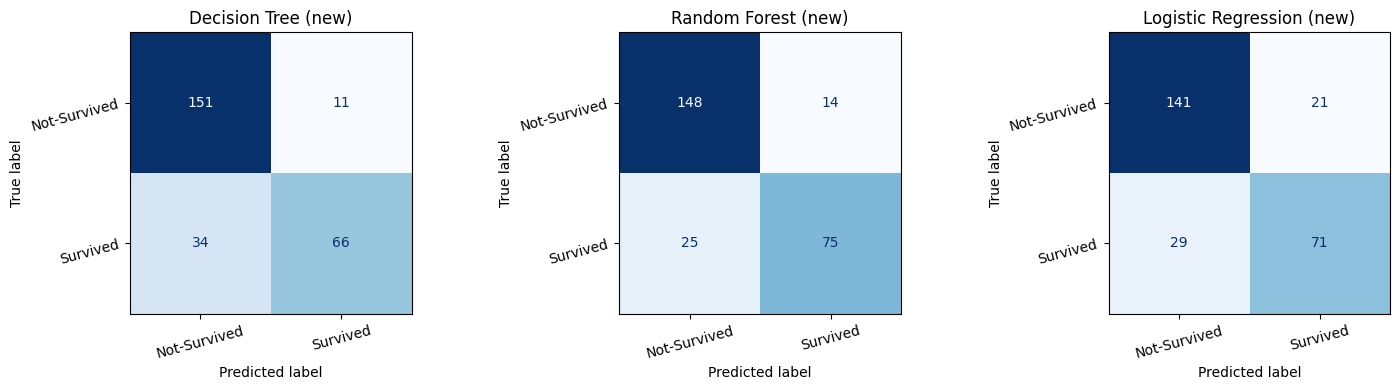

In [ ]:
# ── Confusion matrix for the re-trained models ──────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (model_name, y_pred) in zip(axes, [
        ("Decision Tree (new)", y_pred_dt_new),
        ("Random Forest (new)", y_pred_rf_new),
        ("Logistic Regression (new)", y_pred_lr_new)]):
    cmd = ConfusionMatrixDisplay.from_predictions(y_test_new, y_pred, ax=ax, cmap="Blues",
                                                   colorbar=False)
    ax.set_title(model_name)
    ax.set_xticklabels(labels, rotation=15)
    ax.set_yticklabels(labels, rotation=15)
plt.tight_layout()
plt.show()

## 🔥 Part 2 — Introduction to PyTorch

We will train a neural network on the **Digits dataset** (8×8 grayscale images of handwritten digits, 10 classes).

PyTorch provides the elegantly designed modules and classes [torch.nn](https://pytorch.org/docs/stable/nn.html), [torch.optim](https://pytorch.org/docs/stable/optim.html), [Dataset](https://pytorch.org/docs/stable/data.html?highlight=dataset#torch.utils.data.Dataset), and [DataLoader](https://pytorch.org/docs/stable/data.html?highlight=dataloader#torch.utils.data.DataLoader)
to help you create and train neural networks.

In order to fully utilize their power and customize them for your problem, you need to really understand exactly what they're doing. To develop this understanding, we will first train basic neural net on the digits data set without using any features from these models; we will initially only use the most basic PyTorch tensor functionality. Then, we will incrementally add features from:
1. ``torch.nn``
2. ``torch.optim``
3. ``Dataset``
4. ``DataLoader``

We will add one module at a time, showing exactly what each module does, and how it makes the code either more concise, or more flexible.

We'll incrementally build our code from scratch towards idiomatic PyTorch:

| Step | What we add |
|------|-------------|
| 2.1 | Data loading & visualisation |
| 2.3 | Preprocessing |
| 2.3 | Model from scratch (raw tensors) |
| 2.4 | `torch.nn.functional` |
| 2.5-2.6 | `nn.Module` + `nn.Linear` |
| 2.7 | `torch.optim` |
| 2.8 | `Dataset` + `DataLoader` |
| 2.9-2.10 | Validation loop + early stopping |
| 2.12 | GPU support |
 2.13 | Visualisation |

### 2.1 — Data Loading & Visualisation

In [ ]:
import torch
import torch.nn.functional as F
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import numpy as np
import matplotlib.pyplot as plt

# ── Load ──────────────────────────────────────────────────────
#### START CODE HERE ####
x, y = load_digits(return_X_y=True, as_frame=True)
n_samples, n_features = x.shape
n_classes = len(np.unique(y))
#### END CODE HERE ####

print(f"Samples: {n_samples} | Features: {n_features} | Classes: {n_classes}")
x.describe()

Samples: 1797 | Features: 64 | Classes: 10


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
count,1797.0,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,...,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000
mean,0.0,0.303840,5.204786,11.835838,11.848080,5.781859,1.362270,0.129661,0.005565,1.993879,...,3.725097,0.206455,0.000556,0.279354,5.557596,12.089037,11.809126,6.764051,2.067891,0.364496
std,0.0,0.907192,4.754826,4.248842,4.287388,5.666418,3.325775,1.037383,0.094222,3.196160,...,4.919406,0.984401,0.023590,0.934302,5.103019,4.374694,4.933947,5.900623,4.090548,1.860122
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,1.000000,10.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,11.000000,10.000000,0.000000,0.000000,0.000000
50%,0.0,0.000000,4.000000,13.000000,13.000000,4.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,4.000000,13.000000,14.000000,6.000000,0.000000,0.000000
75%,0.0,0.000000,9.000000,15.000000,15.000000,11.000000,0.000000,0.000000,0.000000,3.000000,...,7.000000,0.000000,0.000000,0.000000,10.000000,16.000000,16.000000,12.000000,2.000000,0.000000
max,0.0,8.000000,16.000000,16.000000,16.000000,16.000000,16.000000,15.000000,2.000000,16.000000,...,16.000000,13.000000,1.000000,9.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000


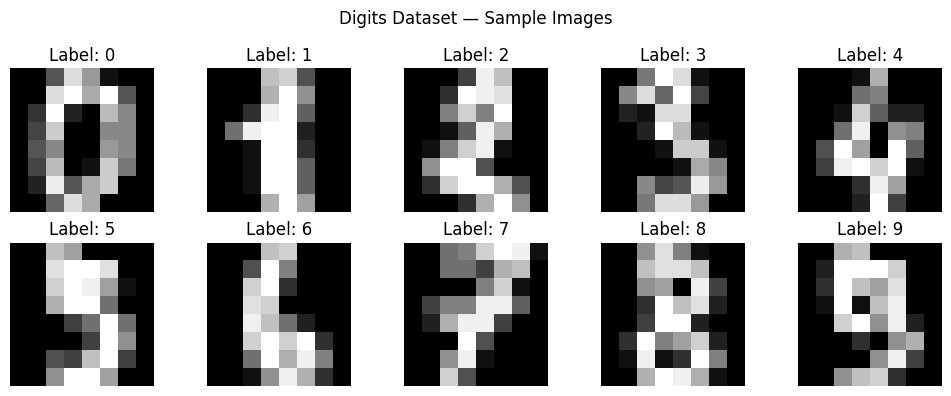

In [ ]:
# Visualise a few examples
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x.iloc[i].values.reshape(8, 8), cmap='gray')
    ax.set_title(f"Label: {y.iloc[i]}")
    ax.axis('off')
plt.suptitle("Digits Dataset — Sample Images")
plt.tight_layout()
plt.show()

### 2.2 — Preprocessing

The preprocessing will consist in

1.   Splitting the data in train and test using `train_test_split` (90-10, with  stratification)
2.   Normalize the data to [0,1] using the `MinMaxScaler`





#### Exercise 2.2

In [ ]:
#@title Exercise 2.2 Solution


#### START CODE HERE ####
# Split 90% train / 10% test, stratified
x_train, x_test, y_train, y_test = train_test_split(
    x.values, y.values, test_size=0.1, stratify=y)
#### END CODE HERE ####

# Normalize to [0, 1] — ALWAYS needed for neural networks
#### START CODE HERE 3 lines of code ####
normalizer = MinMaxScaler()
x_train = normalizer.fit_transform(x_train)
x_test  = normalizer.transform(x_test)
#### END CODE HERE ####

PyTorch uses ``torch.tensor``, rather than numpy arrays, so we need to
convert our data.


In [ ]:
print(f"Train: {x_train.shape} | Test: {x_test.shape}")
print(f"Value range — Train: [{x_train.min():.2f}, {x_train.max():.2f}]")
print(f"Value range — Test: [{x_test.min():.2f}, {x_test.max():.2f}]")

# Convert to PyTorch tensors
x_train = torch.as_tensor(x_train, dtype=torch.float32)
x_test  = torch.as_tensor(x_test,  dtype=torch.float32)
y_train = torch.as_tensor(y_train, dtype=torch.long)
y_test  = torch.as_tensor(y_test,  dtype=torch.long)
print("\n✅ Tensors ready")

Train: torch.Size([1617, 64]) | Test: torch.Size([180, 64])
Value range — Train: [0.00, 1.00]
Value range — Test: [0.00, 2.00]

✅ Tensors ready


### 2.3 — Model from Scratch (raw tensors)

Let's first create a model using nothing but PyTorch tensor operations. We assume you're already familiar with the basics of neural networks.

1. PyTorch provides methods to create random or zero-filled tensors, which we will use to create our weights and bias for a simple linear model.
2. These are just regular tensors, with one very special addition: we tell PyTorch that they require a **gradient**. This causes PyTorch to record all the operations done on the tensor.
3. This allows us and PyTorch to calculate the gradient during back-propagation **automatically**!

Before using any PyTorch modules, we implement everything manually:
- **Weights** & **bias** with `requires_grad=True`
- **Forward pass**: matrix multiply + log-softmax
- **Loss**: negative log-likelihood
- **Backward pass**: `loss.backward()`
- **Update**: manual SGD step inside `torch.no_grad()`


#### The Model

We will use a very simple logistic regression with 10 output nodes (as many as the number of classes).

For the weights, we set ``requires_grad`` after the initialization, since we
don't want that step included in the gradient.

###### To Note:
1. We are initializing the weights here with the [Xavier initialisation](http://proceedings.mlr.press/v9/glorot10a/glorot10a.pdf), by multiplying with 1/sqrt(n_features)).
2. The trailing ``_`` in PyTorch signifies that the operation is performed in-place (``requires_grad_()``)

In [ ]:
# Hyperparameters
lr     = 0.5
epochs = 20
bs     = 64          # mini-batch size
train_samples = x_train.shape[0]

# ── Initialize weights & bias (Xavier-style) ─────────────────
weights = torch.randn(n_features, n_classes) / np.sqrt(n_features)
bias    = torch.randn(n_classes) / np.sqrt(n_features)
weights.requires_grad_()
bias.requires_grad_()

tensor([ 0.0100, -0.1493, -0.1150,  0.0648,  0.1321, -0.1731,  0.2836, -0.0385,
        -0.1030,  0.1379], requires_grad=True)

Thanks to PyTorch's ability to calculate gradients automatically, we can use any standard Python function (or callable object) as a model!

We need a few auxiliary function:

* `log_softmax`: activation function
* `nll_loss`: loss negative log-likelihood
* `model_scratch`: Forward pass, log_softmax(matrix multiplication)
* `accuracy`: accuracy avarage value of



We use the negative log-likelihood as a loss function.
You can find further information on how to compute the cross entropy loss in different scenarios in this [tutorial](https://towardsdatascience.com/cross-entropy-negative-log-likelihood-and-all-that-jazz-47a95bd2e81).


In [ ]:
# ── Helper functions ──────────────────────────────────────────
def log_softmax(x):
    return x - x.exp().sum(-1).log().unsqueeze(-1)

def model_scratch(xb):
    # use xb @ weights or torch.matmul for multiplication
    return log_softmax(xb @ weights + bias)

def nll_loss(output, target):
    # print(output)
    return -output[range(target.shape[0]), target].mean()

def accuracy(out, yb):
    preds = torch.argmax(out, dim=1)
    return (preds == yb).float().mean() * 100

print(f"Initial loss:     {nll_loss(model_scratch(x_train), y_train):.4f}")
print(f"Initial accuracy: {accuracy(model_scratch(x_train), y_train):.2f}%  (random ≈ {100/n_classes:.1f}%)")

Initial loss:     2.3963
Initial accuracy: 6.31%  (random ≈ 10.0%)


#### Exercise 2.3.1

Let's now call our model function on one batch of data (in this case, 64 images).  This is one *forward pass*.  


Note: our predictions won't be any better than random at this stage, since we start with random weights and we have not done any training step.

In [ ]:
#@title Exercise 2.3.1 Solution
bs = 64               # batch size
### START CODE HERE (~2 lines expected)
xb = x_train[0:bs]    # a mini-batch from x
preds = model_scratch(xb)     # predictions
### END CODE
print(preds[0], preds.shape)

tensor([ -5.1181,  -7.3078,  -7.5258,  -8.0046,  -6.3299,  -3.8531,  -0.1712,
        -10.2547,  -2.0661,  -9.4902], grad_fn=<SelectBackward0>) torch.Size([64, 10])


#### Training loop

We can now run a training loop.  For each iteration, we will:

1. select a mini-batch of data (of size ``bs``)
2. use the model to make predictions
3. calculate the loss
4. ``loss.backward()`` computes the gradients of the model, in this case, ``weights`` and ``bias``.
5. update the parameters to optimize the model

Note:

- We do this within the ``torch.no_grad()`` context manager, because we do not want these actions to be recorded for our next calculation of the gradient.  You can read more about how PyTorch's Autograd records operations
[here](https://pytorch.org/docs/stable/notes/autograd.html).
- We then set the gradients to zero, so that we are ready for the next loop. Otherwise, our gradients would record a running tally of all the operations that had happened (i.e. ``loss.backward()`` *adds* the gradients to whatever is already stored, rather than replacing them).


In [ ]:
lr = .5  # learning rate
epochs = 20  # how many epochs to train for
train_samples = x_train.shape[0]

for epoch in range(epochs):
    for i in range((train_samples - 1) // bs + 1):

        ## select input and label batch
        start_i = i * bs
        end_i = start_i + bs
        xb = x_train[start_i:end_i]
        yb = y_train[start_i:end_i]

        ## make predictions and compute loss
        pred = model_scratch(xb)
        loss = nll_loss(pred, yb)

        ## compute gradient through backprop
        loss.backward()

        ## update gradients through SGD
        with torch.no_grad():
            weights -= weights.grad * lr
            bias -= bias.grad * lr
            weights.grad.zero_()
            bias.grad.zero_()
    print(f"Epoch {epoch}: {nll_loss(model_scratch(x_train), y_train):.2f}")



Epoch 0: 0.17
Epoch 1: 0.16
Epoch 2: 0.16
Epoch 3: 0.16
Epoch 4: 0.15
Epoch 5: 0.15
Epoch 6: 0.15
Epoch 7: 0.15
Epoch 8: 0.14
Epoch 9: 0.14
Epoch 10: 0.14
Epoch 11: 0.14
Epoch 12: 0.13
Epoch 13: 0.13
Epoch 14: 0.13
Epoch 15: 0.13
Epoch 16: 0.13
Epoch 17: 0.13
Epoch 18: 0.12
Epoch 19: 0.12


That's it: we've created and trained a minimal neural network (in this case, a logistic regression, since we have no hidden layers) entirely from scratch!

#### Exercise 2.3.2

Let's check the loss and accuracy and compare those to what we got earlier. We expect that the loss will have decreased and accuracy to have increased, and they have.

In [ ]:
#@title Exercise 2.3.2 Solution


## START CODE HERE (~2 lines expected)
print(f"Final loss:     {nll_loss(model_scratch(x_train), y_train):.4f}")
print(f"Final accuracy: {accuracy(model_scratch(x_train), y_train):.2f}%")
### END CODE

Final loss:     0.1231
Final accuracy: 97.65%


### 2.4 — Refactor using `nn`

We will now refactor our code, so that it does the same thing as before, only we'll start taking advantage of PyTorch's ``nn`` classes to make it more concise and flexible.

At each step from here, we should be making our code one or more of:
1. shorter
2. more understandable
3. more flexible

#### Exercise 2.4 Refactor using nn.functional
The first and easiest step is to make our code shorter by replacing our hand-written activation and loss functions with those from ``torch.nn.functional`` (which is generally imported into the namespace ``F`` by convention).

The ``torch.nn.functional`` module contains all the functions in the ``torch.nn`` library (whereas other parts of the library contain classes). As well as a wide range of loss and activation functions, you'll also find here some convenient functions for creating deep neural networks, such as pooling functions.

If you're using negative log likelihood loss and log softmax activation, then Pytorch provides a single function ``F.cross_entropy`` that combines the two. So we can even remove the activation function from our model.

In [ ]:
import torch.nn.functional as F

loss_func = F.cross_entropy

def model(xb):
    return xb @ weights + bias

**Note** that we no longer call ``log_softmax`` in the ``model`` function. Let's confirm that our loss and accuracy are the same as before:



In [ ]:
#@title Exercise 2.4 Solution


### ENTER YOUR CODE HERE (2 line expected)
print(f"Loss after refactoring: {loss_func(model(x_train), y_train)}")
print(f"Accuracy after refactoring: {accuracy(model(x_train), y_train)}")

Loss after refactoring: 0.12306706607341766
Accuracy after refactoring: 97.64997100830078


### 2.5 — Refactor with `nn.Module`


Next up, we'll use ``nn.Module`` (*uppercase M*) and ``nn.Parameter``, for a clearer and more concise training loop.
1. We subclass ``nn.Module`` (which itself is a class and able to keep track of its attributes).  In this case, we want to create a class that holds our weights, bias, and method for the forward step.  ``nn.Module`` has a number of attributes and methods (such as ``.parameters()`` and ``.zero_grad()``) which we will be using for this.
1. Since we're now using an object instead of just using a function, we
first have to instantiate our model:


In [ ]:
from torch import nn

class LogisticRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(n_features, n_classes) / np.sqrt(n_features))
        self.bias = nn.Parameter(torch.randn(n_classes) / np.sqrt(n_features))

    def forward(self, xb):
        return xb @ self.weights + self.bias

model = LogisticRegression()

#### Exercise 2.5.1

Now we can calculate the loss in the same way as before. Note that ``nn.Module`` objects are used as if they are functions (i.e they are *callable*), but behind the scenes Pytorch will call our ``forward`` method automatically, i.e.
```
  def __call__(self, *args, **kwargs):
    return self.forward(args, kwargs)
```

In [ ]:
#@title Exercise 2.5.1 Solution


### ENTER YOUR CODE HERE (1 line expected)
print(loss_func(model(x_train), y_train), accuracy(model(x_train), y_train))

tensor(2.3581, grad_fn=<NllLossBackward0>) tensor(16.3265)


#### Exercise 2.5.2 model.parameters() and model.zero_grad()

Previously for our training loop we had to update the values for each parameter
by name, and manually zero out the grads for each parameter separately, like this:
```
  with torch.no_grad():
      weights -= weights.grad * lr
      bias -= bias.grad * lr
      weights.grad.zero_()
      bias.grad.zero_()
```

Now we can take advantage of ``model.parameters()`` and ``model.zero_grad()`` to make those steps more concise and less prone to the error of forgetting some of our parameters, particularly if we had a more complicated model:
```
  with torch.no_grad():
      for p in model.parameters():
          p -= p.grad * lr
      model.zero_grad()
```


We'll wrap our little training loop in a ``fit`` function so we can run it again later. And we double-check that our loss has gone down:

In [ ]:
#@title Exercise 2.5.2 Solution


def fit():
    for epoch in range(epochs):
        for i in range((train_samples - 1) // bs + 1):
            start_i = i * bs
            end_i = start_i + bs
            xb = x_train[start_i:end_i]
            yb = y_train[start_i:end_i]
            pred = model(xb)
            loss = loss_func(pred, yb)

            loss.backward()

            ### ENTER YOUR CODE HERE (4 lines expected)
            with torch.no_grad():
                for p in model.parameters():
                    p -= p.grad * lr
                model.zero_grad()
        print(f"Epoch: {epoch}, {loss_func(model(x_train), y_train):.2f}")

fit()
print(f"Accuracy: {accuracy(model(x_train), y_train):.2f}")

Epoch: 0, 0.96
Epoch: 1, 0.62
Epoch: 2, 0.47
Epoch: 3, 0.40
Epoch: 4, 0.35
Epoch: 5, 0.32
Epoch: 6, 0.29
Epoch: 7, 0.27
Epoch: 8, 0.25
Epoch: 9, 0.24
Epoch: 10, 0.23
Epoch: 11, 0.22
Epoch: 12, 0.21
Epoch: 13, 0.20
Epoch: 14, 0.20
Epoch: 15, 0.19
Epoch: 16, 0.18
Epoch: 17, 0.18
Epoch: 18, 0.18
Epoch: 19, 0.17
Accuracy: 96.66


### 2.6 — Refactor with `nn.Module` + `nn.Linear`

We continue to refactor our code.  Instead of manually defining and initializing ``self.weights`` and ``self.bias``, and calculating ``xb  @ self.weights + self.bias``, we will instead use the Pytorch class [nn.Linear](https://pytorch.org/docs/stable/nn.html#linear-layers) for a linear layer, which does all that for us.

Pytorch has many types of **predefined layers** that can greatly simplify our code, and often makes it faster too!



#### Exercise 2.6

Instead of managing weights manually, we use:
- `nn.Module` — base class for all models
- `nn.Linear` — a fully-connected layer (handles weights + bias automatically)

In [ ]:
#@title Exercise 2.6 Solution


class LogisticRegression(nn.Module):
    def __init__(self):
        super().__init__()
        #### START CODE HERE (1 lines of code) ####
        self.linear = nn.Linear(n_features, n_classes)
        #### END CODE HERE ####

    def forward(self, xb):
        #### START CODE HERE (1 line of code) ####
        return self.linear(xb)
        #### END CODE HERE ####

model = LogisticRegression()
loss_func = F.cross_entropy  # = log_softmax + nll combined

print(f"Model parameters: {sum(p.numel() for p in model.parameters())}")
print(f"Initial loss:     {loss_func(model(x_train), y_train):.4f}")
print(f"Initial accuracy: {accuracy(model(x_train), y_train):.2f}%")

Model parameters: 650
Initial loss:     2.3451
Initial accuracy: 3.28%


We are still able to use our same ``fit`` method as before.

In [ ]:
fit()
print(f"Loss: {loss_func(model(x_train), y_train)}, Accuracy: {accuracy(model(x_train), y_train)}")

Epoch: 0, 0.97
Epoch: 1, 0.62
Epoch: 2, 0.47
Epoch: 3, 0.40
Epoch: 4, 0.35
Epoch: 5, 0.31
Epoch: 6, 0.29
Epoch: 7, 0.27
Epoch: 8, 0.25
Epoch: 9, 0.24
Epoch: 10, 0.23
Epoch: 11, 0.22
Epoch: 12, 0.21
Epoch: 13, 0.20
Epoch: 14, 0.20
Epoch: 15, 0.19
Epoch: 16, 0.18
Epoch: 17, 0.18
Epoch: 18, 0.17
Epoch: 19, 0.17
Loss: 0.17057859897613525, Accuracy: 96.66048431396484


### 2.7 — Refactor using `torch.optim`

Pytorch also has a package with various optimization algorithms, ``torch.optim``. To implement the previous stochastic gradient descent (SGD) optimization step, we can use ``optim.SGD(params, lr)`` passing to it all the model parameters and the learning rate.





#### Exercise 2.7

We can use the ``step`` method from our optimizer to take a forward step, instead of manually updating each parameter.

This will let us replace our previous manually coded optimization step:
```
  with torch.no_grad():
      for p in model.parameters():
          p -= p.grad * lr
      model.zero_grad()
```

and instead use just:
```
# before the training loop
opt = optim.SGD(model.parameters(), lr=lr)

# in the training loop
opt.step()
opt.zero_grad()
```

``optim.zero_grad()`` resets the gradient to 0 and we need to call it **before** computing the gradient for the next minibatch.

In [ ]:
#@title Exercise 2.7 Solution


from torch import optim
model = LogisticRegression()

### ENTER YOUR CODE HERE (1 line expected)
opt = optim.SGD(model.parameters(), lr=lr)

print(f"Accuracy: {accuracy(model(x_train), y_train)}")

def fit():
    for epoch in range(epochs):
        for i in range((train_samples - 1) // bs + 1):
            start_i = i * bs
            end_i = start_i + bs
            xb = x_train[start_i:end_i]
            yb = y_train[start_i:end_i]
            pred = model(xb)
            loss = loss_func(pred, yb)

            loss.backward()

            ### ENTER YOUR CODE HERE (2 lines expected)
            opt.step()
            opt.zero_grad()
        print(f"Epoch: {epoch}, {loss_func(model(x_train), y_train)}")

fit()
print(f"Accuracy: {accuracy(model(x_train), y_train)}")

Accuracy: 7.359307289123535
Epoch: 0, 0.9774138927459717
Epoch: 1, 0.6193393468856812
Epoch: 2, 0.47611746191978455
Epoch: 3, 0.39882922172546387
Epoch: 4, 0.34973838925361633
Epoch: 5, 0.3153468668460846
Epoch: 6, 0.2896552085876465
Epoch: 7, 0.2695796489715576
Epoch: 8, 0.2533627152442932
Epoch: 9, 0.23992380499839783
Epoch: 10, 0.22855865955352783
Epoch: 11, 0.21878722310066223
Epoch: 12, 0.21026994287967682
Epoch: 13, 0.20275931060314178
Epoch: 14, 0.19607049226760864
Epoch: 15, 0.19006220996379852
Epoch: 16, 0.18462474644184113
Epoch: 17, 0.17967134714126587
Epoch: 18, 0.17513252794742584
Epoch: 19, 0.17095190286636353
Accuracy: 96.84600830078125


### 2.8 — Refactor with `Dataset`, `DataLoader`


#### ``torch.utils.data.Dataset`
PyTorch has an abstract Dataset class in ``torch.utils.data.Dataset``.  A Dataset can be anything that has:
*   a ``__len__`` function (called by Python's standard ``len`` function)
*   a ``__getitem__`` function as a way of indexing into it.

There are many pre-existing datasets in the [torchvision](https://pytorch.org/vision/stable/datasets.html) library. Otherwise you can also create your own.
[This tutorial](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html) walks through a nice example of creating a custom ``FacialLandmarkDataset`` class as a subclass of ``Dataset``.

PyTorch's [TensorDataset](https://pytorch.org/docs/stable/_modules/torch/utils/data/dataset.html#TensorDataset) is a Dataset wrapping tensors. By defining a length and way of indexing, this also gives us a way to iterate, index, and slice along the first dimension of a tensor.

Both ``x_train`` and ``y_train`` can be combined in a single ``TensorDataset``, which will be easier to iterate over and slice.




In [ ]:
from torch.utils.data import TensorDataset
train_ds = TensorDataset(x_train, y_train)

Previously, we had to iterate through minibatches of x and y values separately:
```
    xb = x_train[start_i:end_i]
    yb = y_train[start_i:end_i]
```

Now, we can do these two steps together:
```
    xb,yb = train_ds[i*bs : i*bs+bs] # we access all tensors in the dataset with one slicing
```



In [ ]:
model = LogisticRegression()
opt = optim.SGD(model.parameters(), lr=lr)

print(f"Accuracy: {accuracy(model(x_train), y_train)}")
def fit():
    for epoch in range(epochs):
        for i in range((train_samples - 1) // bs + 1):
            xb, yb = train_ds[i * bs: i * bs + bs]
            pred = model(xb)
            loss = loss_func(pred, yb)

            loss.backward()
            opt.step()
            opt.zero_grad()

        print(f"Epoch: {epoch}, {loss_func(model(x_train), y_train)}")

fit()
print(f"Accuracy: {accuracy(model(x_train), y_train)}")

Accuracy: 11.626468658447266
Epoch: 0, 0.9678528308868408
Epoch: 1, 0.6179147362709045
Epoch: 2, 0.47583577036857605
Epoch: 3, 0.39845675230026245
Epoch: 4, 0.34894508123397827
Epoch: 5, 0.3140684962272644
Epoch: 6, 0.2879195809364319
Epoch: 7, 0.2674420475959778
Epoch: 8, 0.2508816719055176
Epoch: 9, 0.23715247213840485
Epoch: 10, 0.225542813539505
Epoch: 11, 0.2155650407075882
Epoch: 12, 0.20687326788902283
Epoch: 13, 0.19921459257602692
Epoch: 14, 0.19239968061447144
Epoch: 15, 0.18628376722335815
Epoch: 16, 0.18075428903102875
Epoch: 17, 0.17572203278541565
Epoch: 18, 0.1711156666278839
Epoch: 19, 0.1668771505355835
Accuracy: 96.90785217285156


#### ``torch.utils.data.DataLoader`

Pytorch's ``DataLoader`` is responsible for managing batches. You can create a ``DataLoader`` from any ``Dataset``. ``DataLoader`` makes it easier to iterate over batches. Rather than having to use ``train_ds[i*bs : i*bs+bs]``, the DataLoader gives us each minibatch automatically.

Also Shuffling the training data is [important](https://www.quora.com/Does-the-order-of-training-data-matter-when-training-neural-networks) to prevent correlation between batches and overfitting. DataLoader provides the parameter ``shuffle=True`` to do it.

For data intensive training (e.g. big images, or videos), it also allows to employ multiprocessing to load the data in parallel to the training loop with the parameter ``num_workers``.


In [ ]:
from torch.utils.data import DataLoader

train_ds = TensorDataset(x_train, y_train)
train_dl = DataLoader(train_ds, batch_size=bs, shuffle=True)

Previously, our loop iterated over batches (xb, yb) like this:

      for i in range((n-1)//bs + 1):
          xb,yb = train_ds[i*bs : i*bs+bs]
          pred = model(xb)

Now, our loop is much cleaner, as (xb, yb) are loaded automatically from the data loader:

      for xb,yb in train_dl:
          pred = model(xb)



In [ ]:
model = LogisticRegression()
opt = optim.SGD(model.parameters(), lr=lr)

print(f"Accuracy: {accuracy(model(x_train), y_train)}")
def fit():
    for epoch in range(epochs):

        ### ENTER YOUR CODE HERE (2 lines expected)
        for xb, yb in train_dl: # we don't have to specify anymore nor bs nor train_samples
            pred = model(xb)
            loss = loss_func(pred, yb)

            loss.backward()
            opt.step()
            opt.zero_grad()

        print(f"Epoch: {epoch}, {loss_func(model(x_train), y_train)}")

fit()
print(f"Accuracy: {accuracy(model(x_train), y_train)}")

Accuracy: 10.45145320892334
Epoch: 0, 0.9804926514625549
Epoch: 1, 0.6424513459205627
Epoch: 2, 0.4745168089866638
Epoch: 3, 0.39443591237068176
Epoch: 4, 0.34620192646980286
Epoch: 5, 0.3117603361606598
Epoch: 6, 0.2893746793270111
Epoch: 7, 0.26746025681495667
Epoch: 8, 0.24886393547058105
Epoch: 9, 0.23626300692558289
Epoch: 10, 0.22509369254112244
Epoch: 11, 0.21536485850811005
Epoch: 12, 0.20595745742321014
Epoch: 13, 0.20124828815460205
Epoch: 14, 0.1945863962173462
Epoch: 15, 0.1864667385816574
Epoch: 16, 0.18110127747058868
Epoch: 17, 0.1749991923570633
Epoch: 18, 0.17208686470985413
Epoch: 19, 0.16700983047485352
Accuracy: 96.96969604492188


In [ ]:
# Build DataLoaders
x_tr, x_val, y_tr, y_val = train_test_split(x_train, y_train, test_size=0.1, stratify=y_train)

train_ds  = TensorDataset(x_tr, y_tr)
val_ds    = TensorDataset(x_val, y_val)
train_dl  = DataLoader(train_ds, batch_size=bs, shuffle=True)
val_dl    = DataLoader(val_ds,   batch_size=bs*2)

print(f"Train batches: {len(train_dl)} | Val batches: {len(val_dl)}")

Train batches: 23 | Val batches: 2


Thanks to Pytorch's ``nn.Module``, ``nn.Parameter``, ``Dataset``, and ``DataLoader``,
our training loop is now dramatically smaller and easier to understand. Let's
now try to add the basic features necessary to create effective models in practice.

### 2.9 —  Add validation

So far, we were just trying to get a reasonable training loop set up for use on our training data.  In reality, you **always** should also have a [validation set](https://www.fast.ai/2017/11/13/validation-sets/), in order to identify if you are overfitting. We will extract it from the training set and use it to evaluate the model at the end of each epoch.

We'll use a batch size for the test set that is twice as large as that for the training set. This is because the validation set does not need backpropagation and thus takes less memory (it doesn't need to store the gradients). We take advantage of this to use a larger batch size and compute the loss more quickly by inserting the validation loop in a ``with torch.no_grad():``.



In [ ]:
x_train, x_valid, y_train, y_valid = train_test_split(x_train, y_train, test_size=0.1, stratify=y_train)

train_ds = TensorDataset(x_train, y_train)
train_dl = DataLoader(train_ds, batch_size=bs, shuffle=True)

valid_ds = TensorDataset(x_valid, y_valid)
valid_dl = DataLoader(valid_ds, batch_size=bs * 2) # No need to shuffle the Validation set

We will calculate and print the validation loss at the end of each epoch.

Note that we always call ``model.train()`` before training, and ``model.eval()`` before inference, because these are used by some layers (not employed here) such as ``nn.BatchNorm2d`` and ``nn.Dropout`` to ensure appropriate behaviour for these different phases.


#### Exercise 2.9

Add the validation set in the training loop below.

In [ ]:
#@title Exercise 2.9 Solution


model = LogisticRegression()
opt = optim.SGD(model.parameters(), lr=lr)

def fit():
    for epoch in range(epochs):
        ### ENTER YOUR CODE HERE (1 line expected)
        model.train()

        for xb, yb in train_dl:
            pred = model(xb)
            loss = loss_func(pred, yb)

            loss.backward()
            opt.step()
            opt.zero_grad()


        ### ENTER YOUR CODE HERE (6-8 lines expected)
        model.eval()
        with torch.no_grad():
            valid_losses, valid_accs = [], []
            for xb, yb in valid_dl:
                valid_losses.append(loss_func(model(xb), yb))
                valid_accs.append(accuracy(model(xb), yb))

        print(f"Epoch {epoch:.2f}: Val Loss {np.mean(valid_losses):.2f}, "
              f"Val Acc: {np.mean(valid_accs):.2f}")

fit()


Epoch 0.00: Val Loss 1.21, Val Acc: 74.84
Epoch 1.00: Val Loss 0.81, Val Acc: 78.75
Epoch 2.00: Val Loss 0.67, Val Acc: 80.61
Epoch 3.00: Val Loss 0.59, Val Acc: 85.89
Epoch 4.00: Val Loss 0.51, Val Acc: 84.33
Epoch 5.00: Val Loss 0.47, Val Acc: 86.19
Epoch 6.00: Val Loss 0.44, Val Acc: 87.66
Epoch 7.00: Val Loss 0.41, Val Acc: 88.05
Epoch 8.00: Val Loss 0.42, Val Acc: 87.27
Epoch 9.00: Val Loss 0.39, Val Acc: 86.19
Epoch 10.00: Val Loss 0.37, Val Acc: 88.05
Epoch 11.00: Val Loss 0.35, Val Acc: 89.52
Epoch 12.00: Val Loss 0.33, Val Acc: 88.05
Epoch 13.00: Val Loss 0.33, Val Acc: 88.05
Epoch 14.00: Val Loss 0.32, Val Acc: 89.91
Epoch 15.00: Val Loss 0.32, Val Acc: 90.99
Epoch 16.00: Val Loss 0.30, Val Acc: 90.99
Epoch 17.00: Val Loss 0.30, Val Acc: 89.52
Epoch 18.00: Val Loss 0.29, Val Acc: 90.99
Epoch 19.00: Val Loss 0.29, Val Acc: 91.77


### 2.10 —  Saving best model: early stopping
It may have happend that the model has reached the highest validation accuracy (and/or lower validation loss) not at the last epoch. It means that the model overfitted the training data.

A possible way to avoid this phenomenon is to save the model achieving the best validation accuracy (other possible solutions includes reducing the learning rate and decreasing the number of training epochs).

There exists two possible way to do it in pytorch. ``torch.save()`` and ``torch.load()`` can be used with any kind of objects. Torch will serialized this object through pickle. However, if the code generating the object is modified the code might brake in several ways. To avoid this issue, torch provides another couple of functions, ``model.state_dict()`` and ``model.load_state_dict()``, which only save and load the weights of the network.

    torch.save(model.state_dict(), "./best_model.pt")
    model.load_state_dict(torch.load("./best_model.pt"))

For further information on this topic, please read this [tutorial](https://pytorch.org/tutorials/beginner/saving_loading_models.html).


#### Exercise 2.10

Save the best model in the training loop below.

In [ ]:
#@title Exercise 2.10 Solution


model = LogisticRegression()
opt = optim.SGD(model.parameters(), lr=lr)

def fit():
    best_acc = 0.
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_dl:
            pred = model(xb)
            loss = loss_func(pred, yb)

            loss.backward()
            opt.step()
            opt.zero_grad()

        model.eval()
        with torch.no_grad():
            valid_losses, valid_accs = [], []
            for xb, yb in valid_dl:
                valid_losses.append(loss_func(model(xb), yb))
                valid_accs.append(accuracy(model(xb), yb))

            if best_acc < np.mean(valid_accs):

                ### ENTER YOUR CODE HERE - SAVE MODEL (1 line expected)
                torch.save(model.state_dict(), "./best_model.pt")

                best_acc = np.mean(valid_accs)

        print(f"Epoch {epoch}: Loss {np.mean(valid_losses):.2f},  \
                Acc: {np.mean(valid_accs):.2f}")


    ### ENTER YOUR CODE HERE (2 lines expected)
    model.load_state_dict(torch.load("./best_model.pt"))

    model.eval()
    print(f"Best Valid Acc: {np.mean([accuracy(model(xb), yb) for xb, yb in valid_dl]):.2f}")

fit()


Epoch 0: Loss 1.12,                  Acc: 78.26
Epoch 1: Loss 0.77,                  Acc: 83.64
Epoch 2: Loss 0.61,                  Acc: 87.27
Epoch 3: Loss 0.56,                  Acc: 83.25
Epoch 4: Loss 0.49,                  Acc: 85.11
Epoch 5: Loss 0.45,                  Acc: 85.11
Epoch 6: Loss 0.42,                  Acc: 86.19
Epoch 7: Loss 0.41,                  Acc: 88.05
Epoch 8: Loss 0.38,                  Acc: 88.44
Epoch 9: Loss 0.35,                  Acc: 89.52
Epoch 10: Loss 0.34,                  Acc: 90.99
Epoch 11: Loss 0.34,                  Acc: 89.52
Epoch 12: Loss 0.33,                  Acc: 89.52
Epoch 13: Loss 0.31,                  Acc: 89.52
Epoch 14: Loss 0.31,                  Acc: 89.52
Epoch 15: Loss 0.30,                  Acc: 92.85
Epoch 16: Loss 0.29,                  Acc: 89.52
Epoch 17: Loss 0.29,                  Acc: 91.38
Epoch 18: Loss 0.28,                  Acc: 92.85
Epoch 19: Loss 0.29,                  Acc: 89.52
Best Valid Acc: 92.85


Was it useful to early stop the training? Is the best accuracy the same as the one at the last epoch?

Finally, we test the model on the test set to see if it generalizes well also there.
**Note**: There might be a discrepancy between the validation and test accuracy, but it should **not** be too large.

In [ ]:
model = model.cpu()

### ENTER YOUR CODE HERE (2 lines expected)
test_dl = DataLoader(TensorDataset(x_test, y_test), batch_size=bs * 2)
print(f"Test Acc: {np.mean([accuracy(model(xb), yb) for xb, yb in test_dl]):.2f}")

Test Acc: 95.34


### Final idiomatic PyTorch training loop


The **final idiomatic PyTorch training loop** uses:
- `optim.SGD` — takes one optimizer step with `opt.step()` and resets gradients with `opt.zero_grad()`
- `TensorDataset` — wraps tensors into an iterable dataset
- `DataLoader` — handles mini-batching and shuffling automatically

In [ ]:
# Build DataLoaders
x_tr, x_val, y_tr, y_val = train_test_split(x_train, y_train, test_size=0.1, stratify=y_train)

train_ds  = TensorDataset(x_tr, y_tr)
val_ds    = TensorDataset(x_val, y_val)
train_dl  = DataLoader(train_ds, batch_size=bs, shuffle=True)
val_dl    = DataLoader(val_ds,   batch_size=bs*2)

print(f"Train batches: {len(train_dl)} | Val batches: {len(val_dl)}")

Train batches: 21 | Val batches: 2


In [ ]:
model = LogisticRegression()
opt = optim.SGD(model.parameters(), lr=lr)


history = {"train_loss": [], "val_loss": [], "val_acc": []}

def fit(model, opt, train_dl, val_dl, epochs=20):
    best_acc, best_state = 0., None

    for epoch in range(epochs):
        # ── Training phase ────────────────────────────────────
        model.train()
        for xb, yb in train_dl:
            pred = model(xb)
            loss = loss_func(pred, yb)
            loss.backward()

            opt.step()
            opt.zero_grad()

        # ── Validation phase ──────────────────────────────────
        model.eval()
        with torch.no_grad():
            val_losses, val_accs = [], []
            for xb, yb in val_dl:
                val_losses.append(loss_func(model(xb), yb).item())
                val_accs.append(accuracy(model(xb), yb).item())

        avg_val_loss = np.mean(val_losses)
        avg_val_acc  = np.mean(val_accs)

        # Early stopping: save best model
        if avg_val_acc > best_acc:
            best_acc   = avg_val_acc
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        history["val_loss"].append(avg_val_loss)
        history["val_acc"].append(avg_val_acc)

        if epoch % 5 == 0 or epoch == epochs-1:
            print(f"Epoch {epoch:2d} | Val Loss: {avg_val_loss:.3f} | Val Acc: {avg_val_acc:.1f}%")

    # Restore best checkpoint
    model.load_state_dict(best_state)
    print(f"\n✅ Best Val Acc: {best_acc:.2f}%")
    return model

model = fit(model, opt, train_dl, val_dl, epochs=epochs)

Epoch  0 | Val Loss: 1.087 | Val Acc: 85.9%
Epoch  5 | Val Loss: 0.315 | Val Acc: 94.9%
Epoch 10 | Val Loss: 0.223 | Val Acc: 96.1%
Epoch 15 | Val Loss: 0.189 | Val Acc: 96.4%
Epoch 19 | Val Loss: 0.169 | Val Acc: 96.4%

✅ Best Val Acc: 96.44%


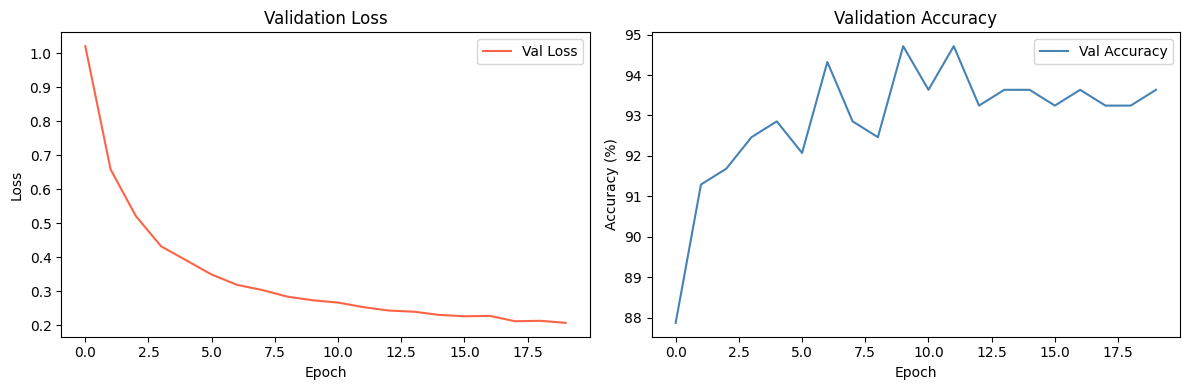

In [ ]:
# Plot training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history["val_loss"], label="Val Loss", color="tomato")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.set_title("Validation Loss"); ax1.legend()
ax2.plot(history["val_acc"],  label="Val Accuracy", color="steelblue")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy (%)"); ax2.set_title("Validation Accuracy"); ax2.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Final evaluation on the TEST set
test_dl = DataLoader(TensorDataset(x_test, y_test), batch_size=bs*2)
model.eval()
with torch.no_grad():
    test_acc = np.mean([accuracy(model(xb), yb).item() for xb, yb in test_dl])
print(f"🎯 Test Accuracy: {test_acc:.2f}%")

🎯 Test Accuracy: 93.60%


### 2.11 — GPU Support


If you're lucky enough to have access to a CUDA-capable GPU you can use it to speed up your code. To do so in COLAB you can change *runtime type* in the *Runtime* dropdown menu to enable GPU computation. After changing the runtime type you will need to rerun the whole notebook beacause all variables will be lost (*Runtime* -> *Run all*).

Let's check that your GPU is working with Pytorch. It should print ``True`` if everything is set up correctly.

In [ ]:
print(torch.cuda.is_available())

Let's then create a device object for it:


In [ ]:
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Finally, we can move our model and our data to the GPU.
Generally dataset do not fit in the GPU, so we need to move only the batches inside the training/validation loops:

    xb = xb.to(dev)
    yb = yb.to(dev)

In [ ]:
model = LogisticRegression().to(dev)
opt = optim.SGD(model.parameters(), lr=lr)

def fit():
    best_acc = 0.
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_dl:

            xb, yb = xb.to(dev), yb.to(dev)
            pred = model(xb)
            loss = loss_func(pred, yb)

            loss.backward()
            opt.step()
            opt.zero_grad()

        model.eval()
        with torch.no_grad():
            valid_losses, valid_accs = [], []
            for xb, yb in valid_dl:

                xb, yb = xb.to(dev), yb.to(dev)
                valid_losses.append(loss_func(model(xb), yb).cpu())
                valid_accs.append(accuracy(model(xb), yb).cpu())

            if best_acc < np.mean(valid_accs):
                torch.save(model.state_dict(), "./best_model.pt")
                best_acc = np.mean(valid_accs)

        print(f"Epoch {epoch}: Loss {np.mean(valid_losses):.2f}, "
              f"Acc: {np.mean(valid_accs):.2f}")
    model.load_state_dict(torch.load("./best_model.pt"))
    model.eval()
    print(f"Best Valid Acc: {np.mean([accuracy(model(xb.to(dev)), yb.to(dev)).cpu() for xb, yb in valid_dl]):.2f}")

fit()

Using device: cpu


### 2.12 — Visualising What the Model Learned

On a logistic regression we can directly visualize both biases and weights! We will reuse the same ``im.show()`` function that we used before to visualize the learnt weights.

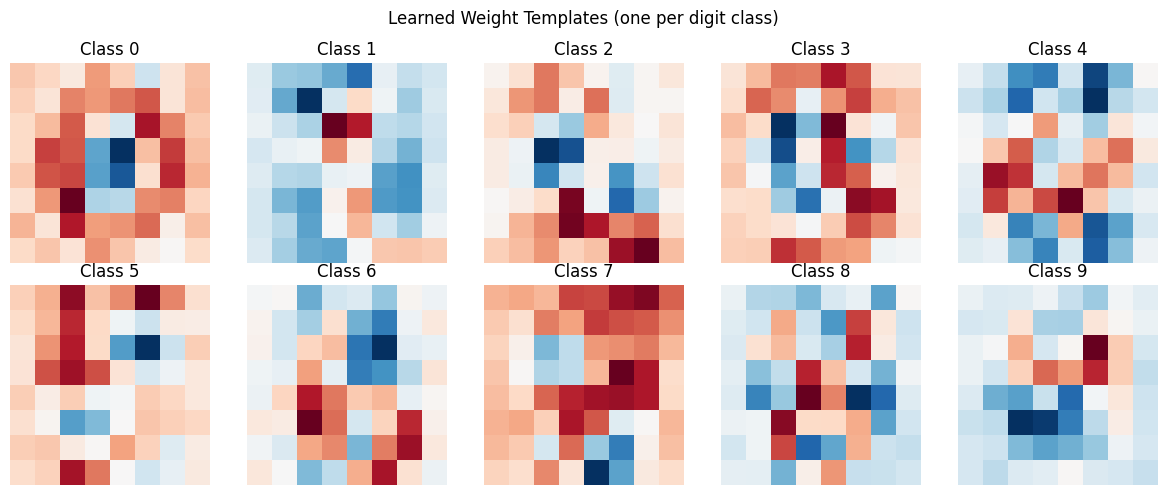

In [ ]:
# Weight visualization: each row is the 'template' for one digit class
learnt_weights = model.lin.weight.detach()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(learnt_weights[i].reshape(8, 8), cmap='RdBu_r')
    ax.set_title(f"Class {i}")
    ax.axis('off')
plt.suptitle("Learned Weight Templates (one per digit class)")
plt.tight_layout()
plt.show()

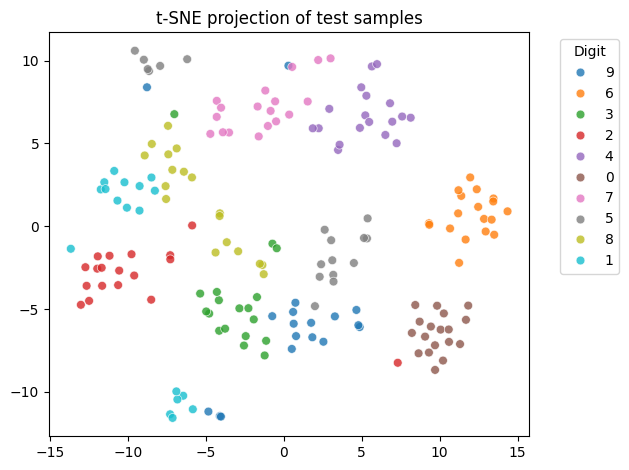

In [ ]:
# t-SNE: visualise how well the model separates the classes in feature space
from sklearn.manifold import TSNE
import seaborn as sns

model.eval()
with torch.no_grad():
    projected = TSNE(n_components=2, init='pca', learning_rate='auto',
                     perplexity=30, random_state=42).fit_transform(x_test.numpy())

sns.scatterplot(x=projected[:,0], y=projected[:,1],
                hue=[str(y.item()) for y in y_test],
                palette='tab10', s=40, alpha=0.8)
plt.title("t-SNE projection of test samples")
plt.legend(title="Digit", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

---

## 📝 Summary

### Part 1 — Scikit-learn Pipeline

| Step | Key function |
|------|-------------|
| Split | `train_test_split(..., stratify=y)` |
| Missing values | `fillna()` / `SimpleImputer` |
| Encoding | `LabelEncoder`, `pd.get_dummies` |
| Scaling | `StandardScaler().fit_transform(X_train)` + `.transform(X_test)` |
| Evaluation | `classification_report`, `ConfusionMatrixDisplay` |

### Part 2 — PyTorch

| Component | Purpose |
|-----------|---------|
| `nn.Module` | Base class for models |
| `nn.Linear` | Fully-connected layer |
| `F.cross_entropy` | Combined softmax + NLL loss |
| `torch.optim.SGD` | Gradient descent optimizer |
| `TensorDataset` | Wraps tensors as a dataset |
| `DataLoader` | Auto mini-batching & shuffling |
| `model.train()` / `.eval()` | Toggle training/inference mode |
| `model.state_dict()` | Save/load model weights |

---

### 🔍 Final Reflection Questions

1. Why should you **never** fit a scaler on the test set?
2. In PyTorch, what does `loss.backward()` compute? What does `opt.zero_grad()` do and why is it necessary?
3. When is early stopping useful? What is its risk?
4. What is the difference between `model.train()` and `model.eval()`?
